# Les pénuries de carburant se propagent-elles comme une épidémie ?
### On étudie plus particulièrement la crise d'octobre 2022 dans les stations-service françaises

Auteurs : Sarah LIABES, Adam Trabelsi

## Sommaire

- Introduction
- I. Données
  - A. Ruptures de carburant par station
  - B. Raffineries, dépôts et dates de grève
  - C. Sources de croisement (chiffres officiels, contours)
  - D. Contrôles qualité et export
- II. Dynamique de la crise
- III. Choc commun ou contagion locale ?
  - A. H1 : distance aux raffineries et dépôts en grève
  - B. H2 : contagion locale entre stations
- IV. Comparaison avec une vraie épidémie : le COVID-19
- Conclusion et limites

## Introduction

À l'automne 2022, des grèves pour les salaires touchent les raffineries et dépôts de TotalEnergies et d'Esso-ExxonMobil, à partir de fin septembre. Au même moment, une remise à la pompe de TotalEnergies, qui s'ajoute à celle de l'État, attire les automobilistes vers ses stations. En quelques jours, les stations-service manquent de carburant dans une grande partie du pays : selon le ministère de la Transition énergétique, près d'une station sur trois est en difficulté à la mi-octobre. Les images de files d'attente et les récits de stations à sec alimentent alors l'idée d'une pénurie qui « se répand » : quand une station ferme, ses clients vont chez la voisine, qui se vide à son tour.

**Problématique.** Pendant la crise d'octobre 2022, les ruptures en stations-service s'expliquent-elles par un choc logistique commun (raffineries et dépôts en grève) ou par une contagion locale, les automobilistes se reportant sur les stations voisines ?

**Hypothèses:**
- **H1 (choc commun) :** les ruptures se concentrent autour des sites en grève et les stations d'une même zone tombent en même temps.
- **H2 (contagion par report) :** une station a plus de chances de tomber en rupture lorsque ses voisines le sont déjà, à approvisionnement comparable.

**Démarche.** Nous traitons la pénurie comme une épidémie : une station « tombe malade » quand elle déclare une rupture. À partir des données officielles de prix et de ruptures de toutes les stations françaises (prix-carburants.gouv.fr), nous construisons des indicateurs inspirés de l'épidémiologie : prévalence, incidence, date de « contamination » des départements, taux d'attaque. Nous les croisons avec la localisation et le calendrier des sites en grève, pour tester H1, et avec la situation des stations voisines, pour tester H2. Enfin, nous comparons la forme de la crise à celle d'une vraie épidémie, le COVID-19 en 2020.

### Configuration

Le code est rangé dans le package `src/penuries/`. Les cellules suivantes l'importent, les données sont téléchargées depuis leurs sources officielles.

In [1]:
import sys

sys.path.append("src")

import pandas as pd

from penuries import collecte, nettoyage, indicateurs, visualisation, contagion, covid

## I. Données

### A. Ruptures de carburant par station

_Source : flux annuel 2022 du site prix-carburants.gouv.fr (données ouvertes du ministère de l'Économie)._

Le flux annuel 2022 recense, pour chaque station-service, ses prix et ses ruptures (carburant, date de début, date de fin si elle est connue). Nous le téléchargeons directement depuis la source officielle, puis nous en extrayons deux tables :
- `df_stations` : une ligne par station (coordonnées, code postal, autoroute ou route, nombre de mises à jour de prix sur la période) ;
- `df_ruptures` : une ligne par épisode de rupture.



In [2]:
chemin_xml = collecte.telecharger_flux_annuel(2022)

df_stations = collecte.lire_stations(chemin_xml)
df_ruptures = collecte.lire_ruptures(chemin_xml)

print(f"{len(df_stations):,} stations, dont {(df_stations['nb_maj_periode'] > 0).sum():,} actives entre septembre et novembre 2022")
print(f"{len(df_ruptures):,} épisodes de rupture au total")
df_ruptures.head()

13,645 stations, dont 9,563 actives entre septembre et novembre 2022
195,032 épisodes de rupture au total


,id_station,latitude,longitude,code_postal,type_route,carburant,debut,fin
0,1000001,4620100,519800,01000,R,GPLc,2017-09-16 09:50:23,NaT
1,1000001,4620100,519800,01000,R,E10,2018-12-13 09:49:49,NaT
2,1000001,4620100,519800,01000,R,E85,2017-09-16 09:50:23,NaT
3,1000001,4620100,519800,01000,R,SP98,2022-10-21 07:51:17,2022-10-21 07:52:49
4,1000001,4620100,519800,01000,R,SP95,2022-10-11 08:31:05,2022-10-11 17:10:56


In [3]:
df_ruptures["debut"].dt.to_period("M").value_counts().sort_index().loc["2022-06":"2022-12"]

debut
2022-06     1654
2022-07     2927
2022-08     2461
2022-09    24528
2022-10    73716
2022-11    36292
2022-12    16000
Freq: M, Name: count, dtype: int64

Par exemple, les ruptures commencées en octobre 2022 sont environ 30 fois plus nombreuses qu'en août, ce qui confirme l'ampleur de la crise. Le fichier contient aussi des ruptures très anciennes sans date de fin (carburants que la station ne vend plus) : nous les traitons dans la partie D.

#### Nettoyage

Nous ne gardons que ce qui sert à répondre à la question :

- **Les stations actives de métropole :** celles qui ont déclaré au moins un prix entre septembre et novembre 2022, avec des coordonnées valides. Le département est déduit du code postal (Corse : 2A pour les codes inférieurs à 20200, 2B au-delà) ; l'outre-mer est exclu.
- **Les ruptures en cours entre le 1er septembre et le 30 novembre 2022**, y compris celles commencées avant le 1er septembre.
- **Les quatre carburants principaux** (gazole, SP95, SP95-E10, SP98) : c'est la définition qu'utilisait le ministère pour compter les stations « en difficulté », ce qui rend nos chiffres comparables aux siens.
- **Les ruptures d'au moins 1 heure et d'au plus 30 jours, avec une date de fin connue.** En dessous d'une heure, il s'agit plutôt d'erreurs de déclaration ; au-delà de 30 jours, ou sans fin connue au 31 décembre, la station a probablement cessé de vendre ce carburant.

In [4]:
df_stations = nettoyage.nettoyer_stations(df_stations)
df_ruptures_periode = nettoyage.nettoyer_ruptures(df_ruptures, df_stations)

print(f"{len(df_stations):,} stations actives dans {df_stations['departement'].nunique()} départements")
print(f"{len(df_ruptures_periode):,} ruptures des carburants principaux entre septembre et novembre 2022")
print(f"Part avec une date de fin connue : {df_ruptures_periode['fin_connue'].mean():.1%}")
df_ruptures_periode["duree_heures"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

9,563 stations actives dans 96 départements
122,506 ruptures des carburants principaux entre septembre et novembre 2022
Part avec une date de fin connue : 92.9%


count    113778.000000
mean        526.589074
std        5369.389942
min           0.000000
5%            1.184958
25%          14.508889
50%          31.371111
75%          79.936944
95%         328.372681
max      155143.188333
Name: duree_heures, dtype: float64

In [5]:
df_ruptures_propres = nettoyage.filtrer_durees(df_ruptures_periode)

part_ecartee = 1 - len(df_ruptures_propres) / len(df_ruptures_periode)
print(f"{len(df_ruptures_propres):,} ruptures conservées ({part_ecartee:.1%} écartées par les filtres de durée)")
df_ruptures_propres["carburant"].value_counts()

106,527 ruptures conservées (13.0% écartées par les filtres de durée)


carburant
Gazole    35143
E10       31523
SP98      29002
SP95      10859
Name: count, dtype: int64

Sur les 9 563 stations actives de métropole (96 départements), 122 506 ruptures des carburants principaux sont en cours entre septembre et novembre 2022. Les filtres en écartent 13,0 % et nous en retenons 106 527 : 7,1 % n'ont pas de date de fin connue au 31 décembre, les autres durent moins d'une heure ou plus de 30 jours. Le cœur des données est conservé.

La durée médiane d'une rupture est de 31 heures : dans la moitié des cas, une station est réapprovisionnée en un peu plus d'une journée. La distribution est très étalée : un quart des ruptures dépasse 80 heures (plus de 3 jours) et 5 % dépassent deux semaines. Ces ruptures longues pourraient concerner les stations dépendant des sites restés en grève le plus longtemps.

### B. Raffineries, dépôts et dates de grève

Table construite à la main (`data/manuel/`), une source citée par ligne.

#### Inventaire et calendrier des sites pétroliers

Pour caractériser le choc d'approvisionnement commun (hypothèse H1), nous avons constitué une table manuelle recensant sept raffineries ou dépôts concernés par les grèves de 2022. Elle indique, pour chaque site, son type, sa localisation, ses dates de début et de fin de grève et une source documentaire. Cette table est versionnée dans `data/manuel/raffineries_depots.csv` ; les dates de grève sont une approximation du calendrier effectif des perturbations logistiques.

In [6]:
from pathlib import Path

fichier_sites = Path("data/manuel/raffineries_depots.csv")
if not fichier_sites.exists():
    raise FileNotFoundError("Fichier des sites introuvable : data/manuel/raffineries_depots.csv")

sites_h1 = pd.read_csv(fichier_sites, dtype={"departement": str}, encoding="utf-8-sig")
colonnes_sites = {"site", "type", "departement", "debut_greve", "fin_greve", "latitude", "longitude"}
assert colonnes_sites.issubset(sites_h1.columns), "Colonnes manquantes dans raffineries_depots.csv"
for col in ["debut_greve", "fin_greve"]:
    sites_h1[col] = pd.to_datetime(sites_h1[col], errors="raise")
for col in ["latitude", "longitude"]:
    sites_h1[col] = pd.to_numeric(sites_h1[col], errors="raise")

print("Sites pétroliers recensés :", len(sites_h1))
colonnes_affichees = [c for c in ["site", "type", "departement", "debut_greve", "fin_greve", "source"] if c in sites_h1]
display(sites_h1[colonnes_affichees])

Sites pétroliers recensés : 7


,site,type,departement,debut_greve,fin_greve,source
0,Port-Jerome,raffinerie,76,2022-09-20,2022-10-14,https://www.spglobal.com/energy/en/news-resear...
1,Fos-sur-Mer,raffinerie,13,2022-09-21,2022-10-13,https://www.lefigaro.fr/conjoncture/en-direct-...
2,Gonfreville,raffinerie,76,2022-09-27,2022-11-02,https://www.spglobal.com/energy/en/news-resear...
3,Donges,raffinerie,44,2022-10-12,2022-10-19,https://www.ladepeche.fr/2022/10/19/penurie-de...
4,La Mede,bioraffinerie,13,2022-09-27,2022-10-19,https://www.lemonde.fr/economie/article/2022/1...
5,Flandres,depot,59,2022-09-27,2022-10-19,https://www.lemonde.fr/economie/article/2022/1...
6,Feyzin,raffinerie,69,2022-09-27,2022-11-08,https://www.lemonde.fr/economie/article/2022/1...


### C. Sources de croisement

Chiffres officiels quotidiens du ministère de la Transition énergétique, contours des départements.

#### Géographie des stations et données de recoupement

Nous avons préparé les contours départementaux (GeoJSON France), puis vérifié la correspondance entre les codes de département des stations et ceux du fond de carte. Le module `src/penuries/geographie.py` rassemble les procédures de préparation ; la vérification détaillée des coordonnées figure également dans `verification_stations.ipynb`.

Les codes départementaux sont conservés en texte afin de ne pas perdre les zéros initiaux (`01`) ni les codes de la Corse (`2A`, `2B`). Une carte n'est pas une preuve de bonne affectation : les stations proches des frontières départementales exigent une vérification particulière.

In [7]:
# Vérifications élémentaires sur la table commune de Sarah
stations_geo_h1 = df_stations[["id_station", "departement", "latitude", "longitude"]].copy()
stations_geo_h1["id_station"] = stations_geo_h1["id_station"].astype(str)
stations_geo_h1["departement"] = stations_geo_h1["departement"].astype(str).str.zfill(2)
stations_geo_h1[["latitude", "longitude"]] = stations_geo_h1[["latitude", "longitude"]].astype(float)

print("Stations distinctes :", stations_geo_h1["id_station"].nunique())
print("Départements distincts :", stations_geo_h1["departement"].nunique())
print("Coordonnées manquantes :", stations_geo_h1[["latitude", "longitude"]].isna().any(axis=1).sum())
print("Identifiants de station dupliqués :", stations_geo_h1["id_station"].duplicated().sum())


Stations distinctes : 9563
Départements distincts : 96
Coordonnées manquantes : 0
Identifiants de station dupliqués : 0


### D. Contrôles qualité et export


#### Audit géographique complémentaire

Sur la version des données examinée lors de la préparation, nous avons contrôlé la cohérence station → département par jointure spatiale. Un premier croisement avec des contours détaillés a fait ressortir 24 observations à examiner (absence d'appariement ou différence avec le département déclaré), sur 9 563 stations. Ce sont des signalements de contrôle, pas nécessairement 24 erreurs : une station proche d'une limite, une géométrie simplifiée ou une différence de codage peut suffire à expliquer un écart. Nous ne modifions pas automatiquement les départements déclarés.

**Traçabilité.** Le notebook de vérification (`verification_stations.ipynb`) garde les contrôles et les résultats exploratoires. Le présent notebook se fonde sur les tables nettoyées par le pipeline commun, déjà construites en partie I.A.

#### Construction de l'indicateur

Nous construisons un panel station × jour : chaque jour du 1er septembre au 30 novembre 2022, à 13 h, nous notons si chaque station a au moins une rupture en cours. Nous en tirons deux indicateurs inspirés de l'épidémiologie :
- la **prévalence** : la part de stations en rupture ce jour-là ;
- l'**incidence** : le nombre de stations qui passent en rupture ce jour-là, alors qu'elles ne l'étaient pas la veille.

In [8]:
panel = indicateurs.panel_station_jour(df_ruptures_propres, df_stations)
panel = indicateurs.ajouter_nouvelles_ruptures(panel)
df_prev = indicateurs.prevalence(panel)
df_prev.head()

,jour,pct_en_rupture,nouvelles_ruptures
0,2022-09-01,0.982955,94
1,2022-09-02,1.934539,138
2,2022-09-03,3.388058,209
3,2022-09-04,5.542194,213
4,2022-09-05,7.267594,306


#### Validation de l'indicateur

Nous définissons une station comme en rupture un jour donné si, à 13 h, elle déclare au moins une rupture en cours sur l'un des quatre carburants principaux. L'heure de 13 h est celle des relevés publiés par le ministère pendant la crise.

Avant d'analyser la crise, nous vérifions que cet indicateur est fiable de trois façons :
1. **Son niveau en temps normal** (septembre, avant les grèves) doit être bas.
2. **La date du pic** doit correspondre à celle des sources officielles.
3. **Son niveau pendant la crise** doit être comparable aux chiffres publiés : ceux du ministère de la Transition énergétique, et ceux de l'analyse indépendante de l'AFP sur les mêmes données publiques.

In [9]:
niveau_normal = df_prev.set_index("jour").loc["2022-09-05":"2022-09-25", "pct_en_rupture"]
pic_prevalence = df_prev.loc[df_prev["pct_en_rupture"].idxmax()]
pic_incidence = df_prev.loc[df_prev["nouvelles_ruptures"].idxmax()]

print(f"Niveau normal (5-25 septembre) : {niveau_normal.min():.1f} % à {niveau_normal.max():.1f} %, moyenne {niveau_normal.mean():.1f} %")
print(f"Pic de prévalence : {pic_prevalence['pct_en_rupture']:.1f} % le {pic_prevalence['jour']:%d/%m}")
print(f"Pic d'incidence : {pic_incidence['nouvelles_ruptures']} nouvelles stations en rupture le {pic_incidence['jour']:%d/%m}")

Niveau normal (5-25 septembre) : 4.4 % à 7.6 %, moyenne 5.9 %
Pic de prévalence : 49.6 % le 16/10
Pic d'incidence : 857 nouvelles stations en rupture le 10/10


In [10]:
df_officiels = pd.read_csv("data/manuel/chiffres_ministere.csv", parse_dates=["date"])

comparaison = df_officiels.merge(
    df_prev[["jour", "pct_en_rupture"]], left_on="date", right_on="jour", how="left"
)
comparaison["ecart_points"] = comparaison["pct_en_rupture"] - comparaison["pourcentage"]
colonnes = ["date", "indicateur", "pourcentage", "pct_en_rupture", "ecart_points", "source"]
comparaison[colonnes].round({"pourcentage": 1, "pct_en_rupture": 1, "ecart_points": 1})

,date,indicateur,pourcentage,pct_en_rupture,ecart_points,source
0,2022-10-05,difficulte_au_moins_un_carburant,12.0,17.2,5.2,https://www.info.gouv.fr/conseil-des-ministres...
1,2022-10-09,difficulte_au_moins_un_carburant,29.7,37.4,7.7,https://www.boursorama.com/bourse/actualites/p...
2,2022-10-10,difficulte_au_moins_un_carburant,29.4,41.4,12.0,https://www.tf1info.fr/politique/en-direct-cri...
3,2022-10-12,difficulte_au_moins_un_carburant,30.8,41.9,11.1,https://www.lemonde.fr/economie/live/2022/10/1...
4,2022-10-15,difficulte_au_moins_un_carburant,27.3,46.2,18.9,https://www.leparisien.fr/economie/penurie-de-...
5,2022-10-19,difficulte_au_moins_un_carburant,20.3,41.1,20.8,https://www.lefigaro.fr/conjoncture/penurie-de...
6,2022-10-20,difficulte_au_moins_un_carburant,16.9,36.5,19.6,https://www.leparisien.fr/economie/penurie-de-...


En temps normal, 4 à 8 % des stations déclarent une rupture, avec de petits pics les dimanches et lundis, faute de livraison le week-end. Pendant la crise, l'indicateur atteint 49,6 % le 16 octobre, soit environ huit fois ce niveau. Le pic des nouvelles ruptures (857 stations le 10 octobre) coïncide avec le pic des chiffres officiels.

Nos pourcentages sont toutefois 5 à 21 points au-dessus de ceux du ministère, et décroissent plus lentement (Voir graphe G0 ci-dessous).

L'analyse de l'AFP, menée sur les mêmes données publiques ([source](https://www.connaissancedesenergies.org/afp/carburants-pres-dune-station-service-sur-trois-en-france-navait-rien-vendre-au-pire-de-la-penurie-selon-une-analyse-afp-221021)), trouve des niveaux proches des nôtres (environ 47 % de stations sans essence ou sans gazole le 17 octobre, 31 % le 20 octobre).

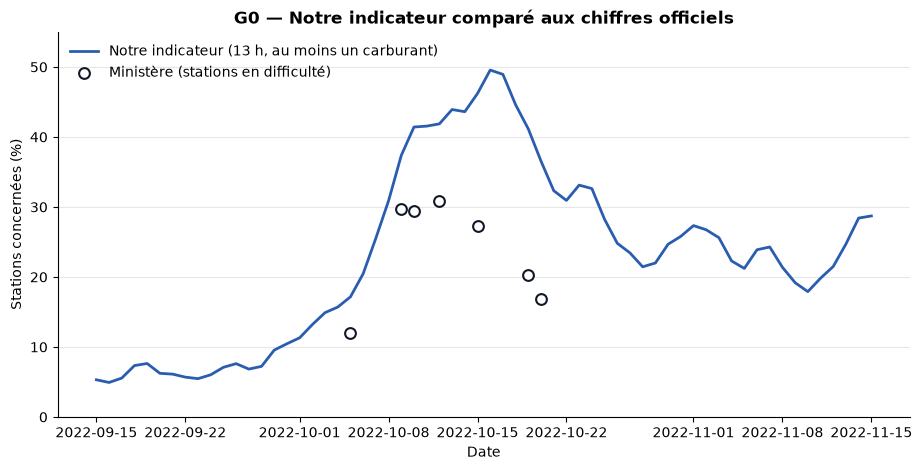

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 5))
periode = df_prev[df_prev["jour"].between("2022-09-15", "2022-11-15")]
ax.plot(periode["jour"], periode["pct_en_rupture"], color="#2a5db0", linewidth=2,
        label="Notre indicateur (13 h, au moins un carburant)")
ax.scatter(df_officiels["date"], df_officiels["pourcentage"], s=60, color="white",
           edgecolor="#111827", linewidth=1.5, zorder=3, label="Ministère (stations en difficulté)")
ax.set_ylim(0, 55)
ax.set_ylabel("Stations concernées (%)")
ax.set_xlabel("Date")
ax.set_title("G0 — Notre indicateur comparé aux chiffres officiels", loc="center", fontweight="bold")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

Notre indicateur suit la même chronologie que les chiffres du ministère, mais à un niveau plus élevé : sur les sept relevés officiels disponibles (du 5 au 20 octobre), il les dépasse en moyenne de 13,6 points.

Surtout, l'écart grandit au fil de la crise:
- **pendant la montée** (5 et 9 octobre), il n'est que de 5 à 8 points ;
- **au plus fort de la crise** (10 et 12 octobre), il atteint 11 à 12 points ;
- **pendant la décrue** (15 au 20 octobre), il atteint 19 à 21 points : les chiffres officiels redescendent à 17 % le 20 octobre, alors que notre indicateur est encore à 36 %.

Le pic est aussi décalé : il est atteint le 12 octobre selon le ministère (30,8 %), le 16 octobre selon notre indicateur (49,6 %).

Deux raisons expliquent ces différences. D'une part, les définitions diffèrent : le ministère excluait les stations déclarant un carburant « non distribué », ce que les données publiques ne permettent pas de distinguer, ce qui place notre indicateur au-dessus dès le départ. D'autre part, les fins de rupture sont déclarées avec retard : une station réapprovisionnée reste en rupture dans le fichier tant qu'elle n'a pas mis à jour ses données. Ce retard s'accumule au fil de la crise, ce qui explique que l'écart grandisse pendant la décrue et que notre pic arrive plus tard.

**Conséquence pour la suite :** notre indicateur surestime le niveau de la pénurie, surtout dans sa seconde moitié, mais en restitue bien le démarrage et la chronologie. C'est ce dont nos analyses ont besoin : H1 repose sur les dates de décollage, et H2 sur les nouvelles ruptures, deux mesures prises pendant la montée de la crise, là où l'écart avec les chiffres officiels est le plus faible.

## II. Dynamique de la crise


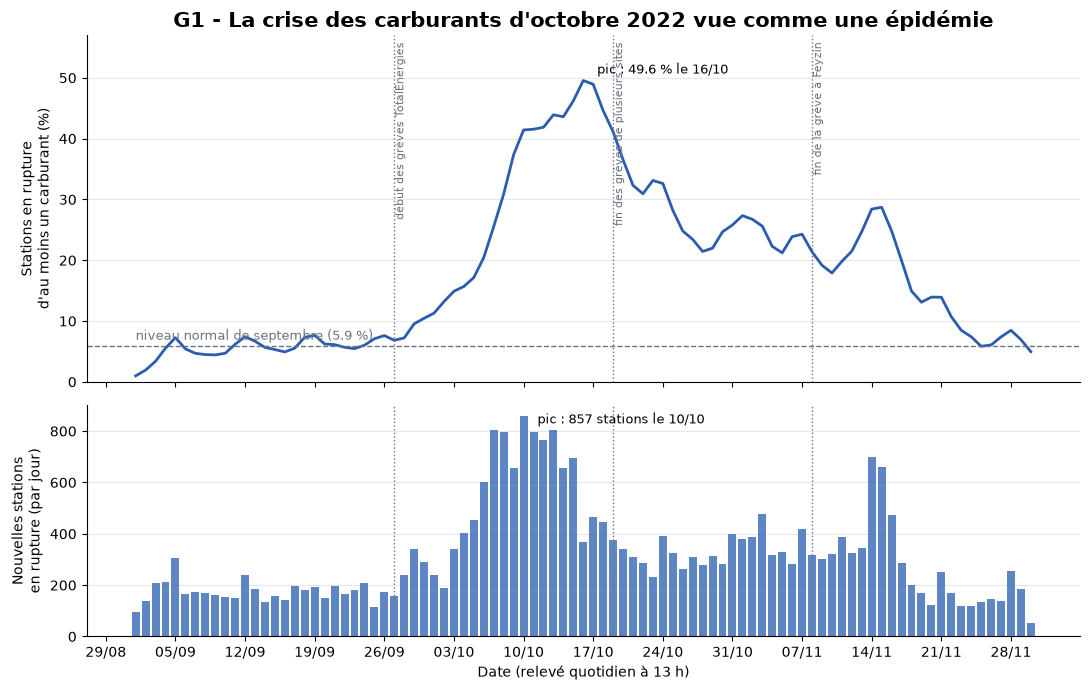

In [12]:

fig = visualisation.courbe_epidemique(
    df_prev,
    niveau_normal=niveau_normal.mean(),
    dates_cles={
        "2022-09-27": "début des grèves TotalEnergies",
        "2022-10-19": "fin des grèves de plusieurs sites",
        "2022-11-08": "fin de la grève à Feyzin",
    },
)


La crise suit une dynamique proche d'une épidémie, en trois temps.

- **Avant la crise (septembre).** Entre 4 et 8 % des stations déclarent une rupture chaque jour (5,9 % en moyenne), et environ 150 à 200 stations y entrent chaque jour : c'est le bruit de fond des ruptures ordinaires, avec de légères hausses les dimanches et lundis, faute de livraison le week-end. La courbe part de presque 0 % le 1er septembre et ne rejoint ce niveau que vers le 5 : c'est un artefact des données. Le fichier source enregistre beaucoup moins de ruptures avant septembre (2 461 ruptures commencées en août, contre environ 180 par jour début septembre), si bien que les ruptures en cours au début du mois sont sous-comptées. Nous ne tenons donc pas compte des premiers jours de septembre dans l'analyse : le niveau normal est calculé du 5 au 25 septembre.
- **Croissance rapide (fin septembre – 9 octobre).** La hausse devient visible quelques jours après le début des grèves (27 septembre), puis s'accélère nettement à partir du 3 octobre : la part de stations en rupture passe d'environ 15 % à 41 % en moins d'une semaine. Les nouvelles ruptures sont alors quatre à cinq fois plus nombreuses qu'en temps normal, avec un pic de 857 stations le 10 octobre, dpendant les jours où les chiffres officiels sont au plus haut.
- **Pic puis décrue lente (10 octobre – fin novembre).** La part de stations en rupture reste au-dessus de 40 % du 9 au 16 octobre et culmine à 49,6 % le 16 octobre, six jours après le pic des nouvelles ruptures : comme dans une épidémie, le nombre de « malades » continue de croître tant que les nouvelles contaminations dépassent les guérisons. Elle redescend ensuite vers 30 % en une semaine, mais se maintient entre 20 et 30 % jusqu'à mi-novembre, avec un rebond à environ 29 % le 14 novembre. Le niveau normal n'est retrouvé que fin novembre.

La crise est donc asymétrique : une dizaine de jours pour monter, plus de six semaines pour se résorber. Une partie de cette lenteur peut venir des fins de rupture déclarées en retard (partie I.D), mais le maintien d'un nombre élevé de nouvelles ruptures fin octobre (300 à 400 par jour, environ le double du niveau normal) montre que la tension sur l'approvisionnement a réellement duré.

Le rebond de mi-novembre est inattendu, car il survient bien après le pic de la crise : nous vérifions dans la partie III s'il est localisé dans quelques départements.

Ce graphique décrit la chronologie de la crise, mais ne permet pas à lui seul de trancher entre choc commun et contagion : la partie III examine où et dans quel ordre les stations tombent en rupture.

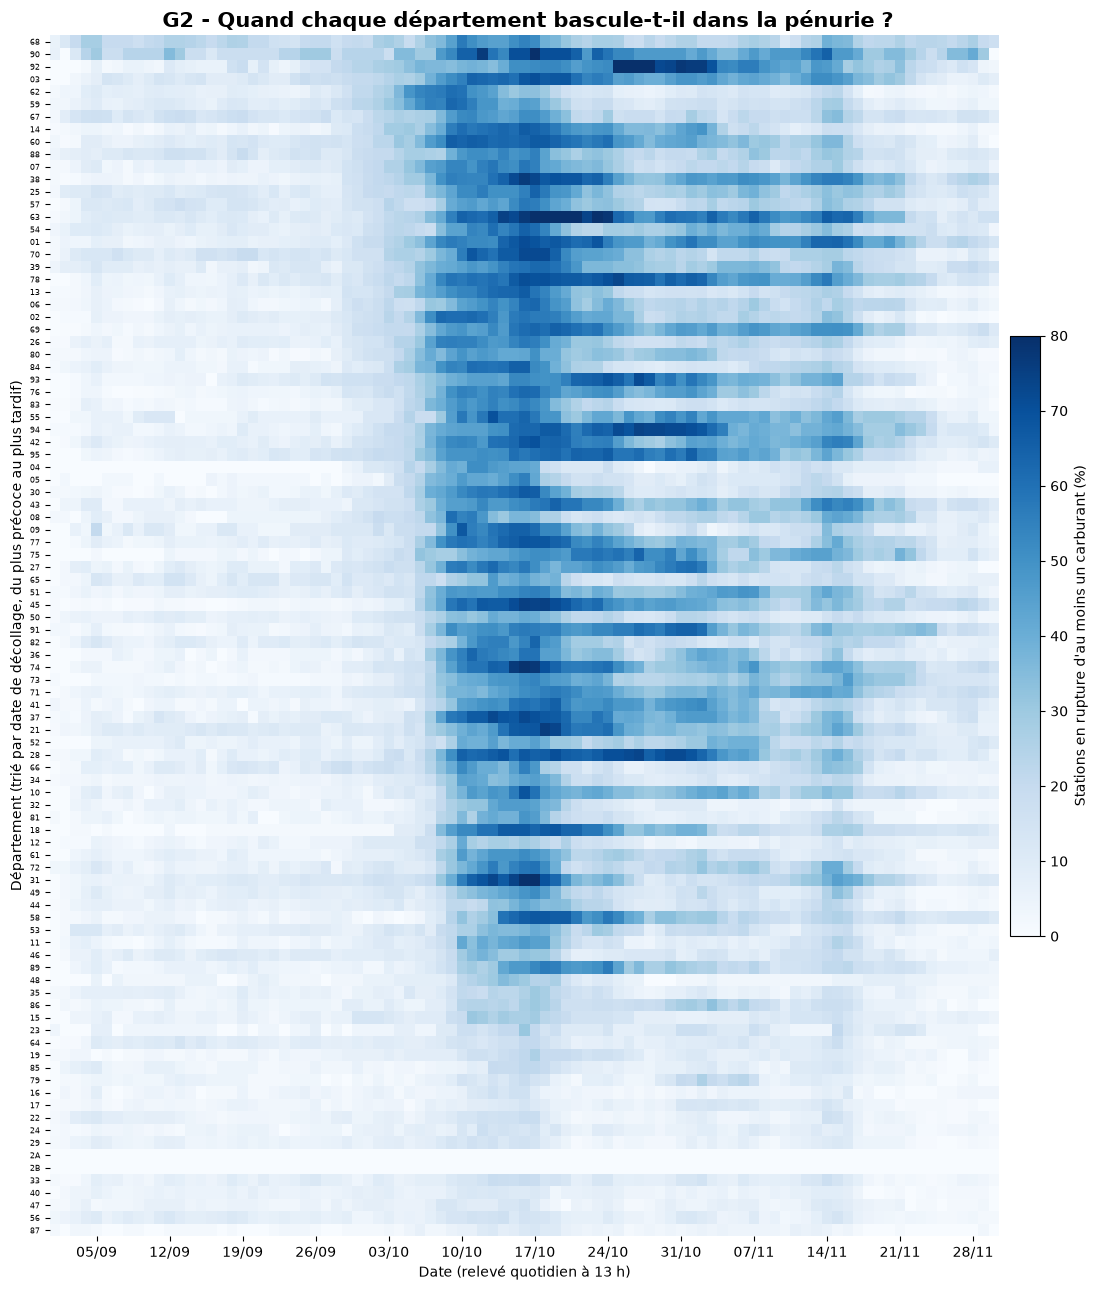

In [13]:
df_prev_dep = indicateurs.prevalence(panel, par="departement")
dates_decollage = indicateurs.date_decollage(df_prev_dep)

fig = visualisation.carte_chaleur_departements(df_prev_dep, dates_decollage)


Chaque ligne est un département, trié du plus précoce au plus tardif selon sa date de décollage (premier jour, à partir du 26 septembre, où au moins 20 % de ses stations sont en rupture).

- **Un basculement concentré sur quelques jours.** Parmi les 84 départements ayant franchi le seuil de 20 %, les premier et troisième quartiles des dates de décollage correspondent respectivement aux 3 et 8 octobre 2022. Cette concentration temporelle suggère un déclenchement largement synchronisé des pénuries, compatible avec l'hypothèse d'un choc logistique commun (H1). Elle ne suffit cependant pas à exclure une contagion locale entre stations.

- **Un démarrage plus précoce dans le Nord.** Le Nord (59) et le Pas-de-Calais (62) franchissent le seuil dès le 30 septembre, avant de nombreux autres départements. Nous confrontons cette précocité à la localisation des raffineries et dépôts en grève dans la partie III.

- **Une intensité et une durée très inégales.** L'Île-de-France, le Centre et l'axe Lyon–Clermont-Ferrand restent fortement touchés jusqu'à début novembre, tandis que certains territoires connaissent un rétablissement plus rapide. Au total, 12 départements métropolitains n'atteignent jamais le seuil de 20 % au cours de la période étudiée. La crise présente donc une forte hétérogénéité géographique.

- **Le rebond de mi-novembre.** Une nouvelle augmentation des ruptures apparaît simultanément dans plusieurs départements. Cette synchronisation peut évoquer une perturbation commune, mais ne permet pas à elle seule de déterminer son origine ni d'écarter des mécanismes locaux.

**Limite méthodologique.** Le Haut-Rhin (68) et le Territoire de Belfort (90) apparaissent en tête du classement, mais leur taux de rupture était déjà relativement élevé en septembre (environ 20 à 25 %). Ils franchissent ainsi le seuil sans nécessairement connaître une nouvelle crise d'une ampleur comparable aux autres départements. Une mesure du décollage définie relativement au niveau initial de chaque département permettrait de mieux tenir compte de cette situation.

**Interprétation.** Le graphique suggère un déclenchement largement synchronisé des pénuries, compatible avec l'hypothèse d'un choc logistique commun (H1). Il met également en évidence des différences territoriales importantes dans l'intensité et la durée de la crise. Nous étudions dans la partie III si ces différences sont associées à la proximité des sites pétroliers en grève (H1) et si les ruptures présentent une dynamique de contagion entre stations voisines (H2).


## III. Choc commun ou contagion locale ?

### A. (H1) Distance aux raffineries et dépôts en grève

**Question.** Les ruptures de carburant sont-elles compatibles avec un **choc logistique commun** ? Si les perturbations de l'approvisionnement partent des sites en grève, les territoires situés à proximité pourraient être touchés plus tôt. Deux outils descriptifs sont mobilisés : G3, des cartes de prévalence par département, et G4, la relation entre la distance à un site en grève et la date de « décollage » des pénuries.

**Unité statistique.** Les stations servent à mesurer la prévalence et les distances ; le test de G4 porte sur les départements. Une corrélation départementale ne doit pas être interprétée comme une causalité au niveau des stations.

#### 1. Distances aux sites pétroliers : construction et contrôle

Nous utilisons les coordonnées des **9 563 stations** et celles des **sept sites** de notre table manuelle. Les distances sont calculées en kilomètres par la formule de Haversine, qui approxime la distance sur la surface terrestre. Le module `src/penuries/distances.py` contient la fonction réutilisable et ses tests élémentaires (dont un calcul Paris–Marseille).

Ici, nous recalculons la distance au **plus proche des sept sites recensés**, indépendamment des dates de grève. Cette première distance décrit la géographie des sites ; le test G4 utilisera, lui, les **sites signalés en grève à la date considérée**.

In [14]:
from penuries.distances import distance_km
import numpy as np

assert stations_geo_h1["id_station"].is_unique, "Une ligne par station est requise."
assert not sites_h1[["latitude", "longitude"]].isna().any().any()

resultats_distances_h1 = []
for station in stations_geo_h1.itertuples(index=False):
    comparaisons = [
        (distance_km(station.latitude, station.longitude, s.latitude, s.longitude), s.site)
        for s in sites_h1.itertuples(index=False)
    ]
    dist, nom_site = min(comparaisons, key=lambda element: element[0])
    resultats_distances_h1.append({
        "id_station": station.id_station,
        "departement": station.departement,
        "site_proche": nom_site,
        "distance_km": float(dist)
    })

df_distances_h1 = pd.DataFrame(resultats_distances_h1)
print("Stations géolocalisées :", len(df_distances_h1))
print("Distances manquantes :", df_distances_h1["distance_km"].isna().sum())
display(df_distances_h1["distance_km"].describe(percentiles=[.25, .50, .75, .90]).round(2).to_frame("km"))
display(df_distances_h1.head())

Stations géolocalisées : 9563
Distances manquantes : 0


,km
count,9563.00
mean,169.80
std,104.62
min,0.44
25%,88.68
50%,149.43
75%,241.20
90%,327.55
max,470.22


,id_station,departement,site_proche,distance_km
0,1000001,01,Feyzin,64.896393
1,1000004,01,Feyzin,65.242931
2,1000007,01,Feyzin,68.486942
3,1000009,01,Feyzin,65.451711
4,1000012,01,Feyzin,64.961975


**Lecture.** La distance mesure une **proximité géographique**, et non le réseau réel d'approvisionnement : la station la plus proche d'une raffinerie ne reçoit pas nécessairement son carburant de celle-ci. Les dépôts et raffineries ne sont pas tous de même nature. Cette variable sert donc à tester un faisceau d'indices pour H1, pas à identifier les circuits logistiques.

#### 2. G3 — Cartes départementales de diffusion des pénuries

Nous reprenons **exactement la mesure de prévalence du notebook commun** : une station est en rupture lorsqu'au moins un des quatre carburants principaux manque **à 13 h**, chaque jour. Pour chaque département, nous divisons le nombre de stations en rupture par le nombre de stations observées.

Les quatre dates retenues sont **19 septembre, 1er octobre, 10 octobre et 20 octobre 2022**. La couleur des départements mesure le pourcentage en rupture, et les croix indiquent les sites dont le calendrier mentionne une grève à la date considérée. Les quatre cartes partagent la même échelle, pour rendre les comparaisons possibles.

In [15]:
# Construire la prévalence départementale à partir du panel déjà produit par Sarah.
# L'affectation départementale vient de df_stations pour éviter toute ambiguïté.
ids_deps_h1 = stations_geo_h1[["id_station", "departement"]]
etat_h1 = panel[["id_station", "jour", "en_rupture"]].copy()
etat_h1["id_station"] = etat_h1["id_station"].astype(str)
etat_h1["jour"] = pd.to_datetime(etat_h1["jour"]).dt.normalize()
assert not etat_h1.duplicated(["id_station", "jour"]).any(), "Doublons dans le panel station-jour"

etat_h1 = etat_h1.merge(ids_deps_h1, on="id_station", how="left", validate="many_to_one")
assert etat_h1["departement"].notna().all(), "Stations sans département après jointure"
etat_h1["en_rupture"] = etat_h1["en_rupture"].fillna(False).astype(bool)

taux_dep_h1 = (
    etat_h1.groupby(["jour", "departement"], observed=True)["en_rupture"]
    .mean().mul(100).rename("taux_rupture_pct").reset_index()
)

# Contrôle : 96 départements et le calendrier d'observation commun.
print("Départements dans le panel :", taux_dep_h1["departement"].nunique())
print("Dates dans le panel :", taux_dep_h1["jour"].nunique())
dates_cartes_h1 = pd.to_datetime(["2022-09-19", "2022-10-01", "2022-10-10", "2022-10-20"])
for jour in dates_cartes_h1:
    sous_table = taux_dep_h1.loc[taux_dep_h1["jour"] == jour]
    print(jour.strftime("%d/%m/%Y"), "— départements au-dessus de 10 % :", int((sous_table["taux_rupture_pct"] > 10).sum()))

Départements dans le panel : 96
Dates dans le panel : 91
19/09/2022 — départements au-dessus de 10 % : 20
01/10/2022 — départements au-dessus de 10 % : 49
10/10/2022 — départements au-dessus de 10 % : 90
20/10/2022 — départements au-dessus de 10 % : 84


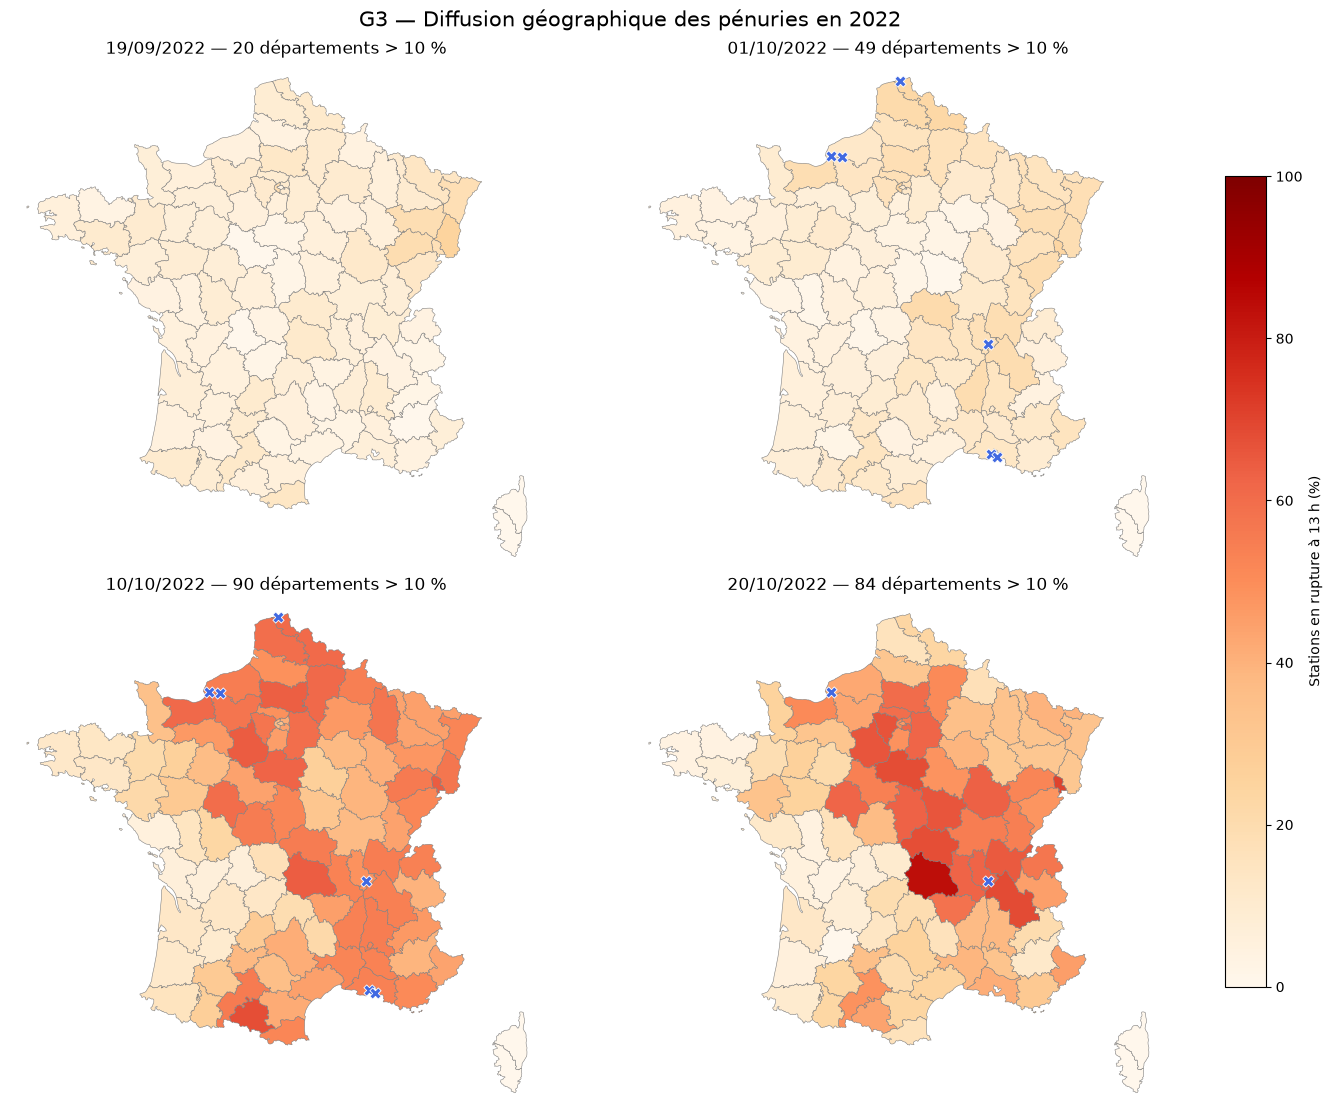

In [16]:
import json
import urllib.request
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

url_geo_h1 = (
    "https://raw.githubusercontent.com/gregoiredavid/france-geojson/"
    "master/departements-version-simplifiee.geojson"
)
with urllib.request.urlopen(url_geo_h1, timeout=30) as reponse:
    geo_h1 = json.load(reponse)

contours_h1 = gpd.GeoDataFrame.from_features(geo_h1["features"], crs="EPSG:4326")
contours_h1["code"] = contours_h1["code"].astype(str)
contours_h1 = contours_h1.loc[contours_h1["code"].isin(stations_geo_h1["departement"].unique()), ["code", "geometry"]]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)
nuancier = "OrRd"
echelle = Normalize(vmin=0, vmax=100)
for ax, jour in zip(axes.flat, dates_cartes_h1):
    valeurs = taux_dep_h1.loc[taux_dep_h1["jour"] == jour, ["departement", "taux_rupture_pct"]]
    carte = contours_h1.merge(valeurs, left_on="code", right_on="departement", how="left", validate="one_to_one")
    carte.plot(column="taux_rupture_pct", ax=ax, cmap=nuancier, vmin=0, vmax=100,
               edgecolor="grey", linewidth=0.4,
               missing_kwds={"color": "lightgrey"})
    sites_actifs = sites_h1.loc[
        (sites_h1["debut_greve"] <= jour) & (sites_h1["fin_greve"] >= jour)
    ]
    ax.scatter(sites_actifs["longitude"], sites_actifs["latitude"],
               marker="X", s=65, color="royalblue", edgecolors="white", linewidths=.6, zorder=5)
    n_dep = int((valeurs["taux_rupture_pct"] > 10).sum())
    ax.set_title(f"{jour:%d/%m/%Y} — {n_dep} départements > 10 %")
    ax.set_xlim(-5.6, 10.0)
    ax.set_ylim(41.2, 51.4)
    ax.set_axis_off()

fig.colorbar(ScalarMappable(norm=echelle, cmap=nuancier), ax=axes.ravel().tolist(),
             shrink=.78, label="Stations en rupture à 13 h (%)")
fig.suptitle("G3 — Diffusion géographique des pénuries en 2022", fontsize=15)

Path("resultats").mkdir(exist_ok=True)
fig.savefig("resultats/G3_cartes_diffusion_13h.png", dpi=220, bbox_inches="tight")
plt.show()

**Interprétation de G3.** Les cartes décrivent l'extension territoriale de la crise et mettent en regard les départements en difficulté et les sites en grève. Elles doivent être lues **avec les taux calculés ci-dessus** : des différences d'heure ou d'échantillon peuvent modifier légèrement les comptes publiés dans les explorations précédentes. La coïncidence spatiale ne démontre pas à elle seule que la grève d'un site est à l'origine des ruptures d'un département.

Le **fond de carte** provient du dépôt public `gregoiredavid/france-geojson` ; les points bleus sont issus de notre table manuelle sourcée.

#### 3. G4 — Distance et date de décollage départementale

Pour rendre le test **cohérent avec la partie II de Sarah**, nous prenons pour analyse principale la même définition de *date de décollage* : **premier jour à partir du 26 septembre 2022 où au moins 20 % des stations du département sont en rupture à 13 h**.

Nous représentons chaque département par la moyenne des coordonnées de ses stations (un **centre moyen**, pas un barycentre économique) puis calculons la distance à vol d'oiseau au **site recensé en grève le plus proche à sa date de décollage**. Le coefficient de Spearman mesure l'association monotone entre distance et retard de décollage, sans supposer une relation linéaire.

**Précaution de sélection.** Un département déjà au-dessus de 20 % le 26 septembre a une date de premier franchissement possiblement antérieure : nous le considérons comme *censuré à gauche* et le retirons du calcul de corrélation. Les départements ne franchissant pas le seuil ou sans site actif à leur date de décollage sont également exclus du test, et leur nombre est indiqué.

In [17]:
from scipy.stats import spearmanr

seuil_h1 = 20.0
debut_observation_h1 = pd.Timestamp("2022-09-26")
franchissements_h1 = taux_dep_h1.loc[
    (taux_dep_h1["jour"] >= debut_observation_h1)
    & (taux_dep_h1["taux_rupture_pct"] >= seuil_h1)
]
premieres_dates_h1 = (
    franchissements_h1.groupby("departement", observed=True)["jour"]
    .min().rename("date_decollage").reset_index()
)
centres_h1 = (
    stations_geo_h1.groupby("departement", as_index=False)[["latitude", "longitude"]]
    .mean()
)
g4_h1 = centres_h1.merge(premieres_dates_h1, on="departement", how="left", validate="one_to_one")
g4_h1["censure_entree"] = g4_h1["date_decollage"].eq(debut_observation_h1)

def proximite_site_actif_h1(ligne):
    date = ligne["date_decollage"]
    if pd.isna(date):
        return pd.Series({"site_actif_plus_proche": None, "distance_site_actif_km": np.nan})
    actifs = sites_h1.loc[(sites_h1["debut_greve"] <= date) & (sites_h1["fin_greve"] >= date)]
    if actifs.empty:
        return pd.Series({"site_actif_plus_proche": None, "distance_site_actif_km": np.nan})
    dist, site = min(
        (distance_km(ligne["latitude"], ligne["longitude"], s.latitude, s.longitude), s.site)
        for s in actifs.itertuples(index=False)
    )
    return pd.Series({"site_actif_plus_proche": site, "distance_site_actif_km": dist})

g4_h1 = pd.concat([g4_h1, g4_h1.apply(proximite_site_actif_h1, axis=1)], axis=1)
g4_h1["jours_depuis_26_sept"] = (g4_h1["date_decollage"] - debut_observation_h1).dt.days
valides_h1 = g4_h1.loc[
    ~g4_h1["censure_entree"]
].dropna(subset=["distance_site_actif_km", "jours_depuis_26_sept"]).copy()

rho_h1, pvalue_h1 = (spearmanr(valides_h1["distance_site_actif_km"],
                                valides_h1["jours_depuis_26_sept"])
                      if len(valides_h1) >= 3 else (np.nan, np.nan))
print("Départements au total :", len(g4_h1))
print("Au-dessus du seuil dès le 26/09 (censurés) :", int(g4_h1["censure_entree"].sum()))
print("N'ayant pas franchi le seuil :", int(g4_h1["date_decollage"].isna().sum()))
print("Sans site actif associé :", int((g4_h1["date_decollage"].notna() & g4_h1["distance_site_actif_km"].isna()).sum()))
print("Départements retenus pour G4 :", len(valides_h1))
print(f"Spearman = {rho_h1:.4f} ; p-value indicative = {pvalue_h1:.3g}")
display(valides_h1[["departement", "date_decollage", "site_actif_plus_proche", "distance_site_actif_km"]].head(10))

Départements au total : 96
Au-dessus du seuil dès le 26/09 (censurés) : 2
N'ayant pas franchi le seuil : 12
Sans site actif associé : 0
Départements retenus pour G4 : 82
Spearman = 0.3921 ; p-value indicative = 0.000269


,departement,date_decollage,site_actif_plus_proche,distance_site_actif_km
0,01,2022-10-03,Feyzin,60.076975
1,02,2022-10-03,Flandres,182.350561
2,03,2022-09-30,Feyzin,152.553332
3,04,2022-10-05,La Mede,108.141102
4,05,2022-10-05,Feyzin,162.049499
5,06,2022-10-03,La Mede,167.326722
6,07,2022-10-02,Feyzin,103.301053
7,08,2022-10-06,Flandres,224.235698
8,09,2022-10-06,Fos-sur-Mer,274.486842
9,10,2022-10-08,Port-Jerome,292.023250


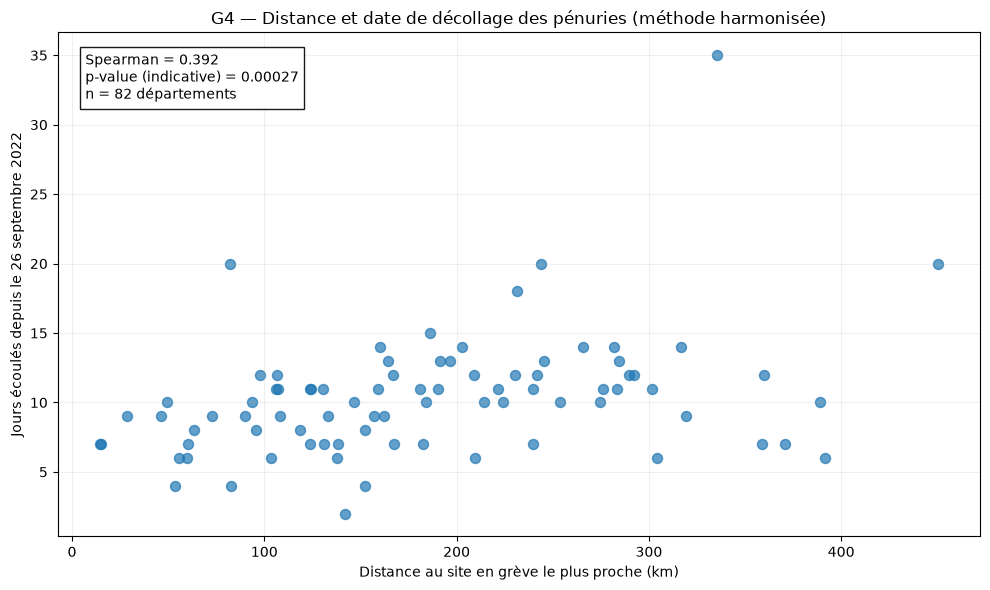

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(valides_h1["distance_site_actif_km"], valides_h1["jours_depuis_26_sept"],
           alpha=.7, s=52)
ax.set_title("G4 — Distance et date de décollage des pénuries (méthode harmonisée)")
ax.set_xlabel("Distance au site en grève le plus proche (km)")
ax.set_ylabel("Jours écoulés depuis le 26 septembre 2022")
ax.text(.03, .96,
        f"Spearman = {rho_h1:.3f}\np-value (indicative) = {pvalue_h1:.2g}\nn = {len(valides_h1)} départements",
        transform=ax.transAxes, va="top", bbox={"facecolor": "white", "alpha": .9})
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig("resultats/G4_distance_decollage_13h_20pct.png", dpi=220, bbox_inches="tight")
g4_h1.to_csv("resultats/G4_departements_13h_20pct.csv", index=False)
plt.show()

#### 4. Sensibilité au seuil de décollage

Une première version exploratoire de G4, avec un relevé à 12 h et un seuil de décollage de 10 %, donnait également une corrélation positive entre la distance aux sites en grève et la date de décollage. Elle reposait sur une extraction antérieure des données et n'est pas reproduite ici : nous ne retenons que la version recalculée ci-dessus (relevé à 13 h, seuil de 20 %), cohérente avec le reste du notebook. Le sens de la relation ne dépend donc pas du seuil retenu.

#### 5. Bilan et limites de H1

Les cartes G3 mettent en évidence la diffusion géographique des pénuries : à 13 h, le nombre de départements présentant plus de 10 % de stations en rupture passe de 20 le 19 septembre à 90 le 10 octobre 2022.

L'analyse G4, réalisée avec un seuil de décollage de 20 %, porte sur 82 départements. Elle révèle une corrélation de Spearman positive et modérée entre la distance aux sites pétroliers en grève et la date de décollage des pénuries (**ρ = 0,3921 ; p-value indicative = 0,000269**).

Ces résultats sont compatibles avec l'hypothèse H1 d'un choc logistique commun : les départements les plus éloignés des sites en grève tendent à être touchés plus tardivement. Ils ne permettent toutefois pas d'établir un lien causal, compte tenu des limites de mesure, de sélection et d'inférence détaillées ci-dessous.

Plusieurs réserves sont essentielles :

- **Mesure des ruptures :** les déclarations peuvent être mises à jour avec retard et un seul carburant manquant suffit à classer une station en rupture ;
- **Distance imparfaite :** la distance à vol d'oiseau, mesurée depuis un centre moyen de stations, ne décrit ni les flux de carburant ni la véritable chaîne logistique ;
- **Calendrier des grèves :** les dates par site sont établies à partir de sources de presse et peuvent ne pas refléter exactement la disponibilité effective des produits ;
- **Sélection des départements :** certains ont déjà franchi le seuil à l'entrée de la période, d'autres ne le franchissent pas ; les exclure peut modifier la corrélation ;
- **Distance définie à la date de décollage :** le groupe des sites « actifs » dépend de la date étudiée, ce qui peut introduire une dépendance mécanique dans le test ;
- **Inférence :** les départements ne sont pas indépendants spatialement. La p-value usuelle du test de Spearman est donc seulement indicative.

**Conclusion partielle.** H1 propose une explication logistique plausible de la synchronisation et de la géographie de la crise. Les analyses restent **descriptives** et ne permettent pas de départager définitivement choc commun et contagion locale : l'hypothèse H2 devra être étudiée dans la section suivante.

**Reproductibilité.** Les données de rupture et de stations sont construites en partie I, les coordonnées et dates des sites figurent dans `data/manuel/raffineries_depots.csv`, les fonctions géographiques sont dans `src/penuries/`, et les figures recalculées sont exportées dans `resultats/`. La cartographie nécessite `geopandas` et l'accès au GeoJSON public lors de la première exécution.

### B. H2 — Contagion locale entre stations



**Question.** Une station a-t-elle plus de chances de tomber en rupture lorsque ses voisines le sont déjà ? C'est ce que prédit l'hypothèse d'une contagion par report des automobilistes : quand une station est à sec, ses clients se reportent sur les stations voisines, qui se vident à leur tour.

**Méthode.** Chaque jour, nous considérons les stations à risque : celles qui n'étaient pas en rupture la veille et qui ont au moins une voisine à moins de 5 km (les 14 % de stations isolées sont exclues). Une station est exposée si au moins une de ses voisines était en rupture la veille ; nous regardons si elle tombe en rupture le jour même. Prendre l'état des voisines la veille garantit que l'exposition précède l'événement.

Deux précautions séparent la contagion du choc commun :
- **À département et jour fixés.** Comparer naïvement les stations exposées et non exposées reviendrait en partie à comparer les départements touchés aux départements épargnés, c'est-à-dire à retrouver H1. Pour chaque station, nous calculons donc son écart au taux de rupture moyen des stations à risque de son département le même jour.
- **En part de voisines.** Une station urbaine a beaucoup de voisines, donc mécaniquement plus de chances d'en avoir une en rupture. Pour l'effet dose-réponse, nous raisonnons en **part** de voisines en rupture.

Enfin, nous comparons la crise (28 septembre – 31 octobre) à septembre (5 – 25 septembre) : un effet de voisinage qui existe déjà en temps normal ne peut pas être attribué à la crise.

In [19]:
paires = indicateurs.paires_voisines(df_stations)
panel = indicateurs.ajouter_voisines_en_rupture(panel, paires)
resultats_h2 = contagion.analyser_h2(panel)

for nom, tableau in resultats_h2.items():
    print(nom)
    display(tableau.round(2))

taux_crise


,taux_attaque_pct,ecart_dep_jour_pts,nb_observations
exposee,,,
False,4.41,-0.56,86698
True,9.00,0.45,108902


taux_normal


,taux_attaque_pct,ecart_dep_jour_pts,nb_observations
exposee,,,
False,2.01,-0.04,109784
True,2.48,0.08,51335


dose_crise


,taux_attaque_pct,ecart_dep_jour_pts,nb_observations
classe_exposition,,,
aucune,4.41,-0.56,86698
jusqu'à 25 %,5.75,0.33,38703
25 à 50 %,8.73,-0.22,42077
50 à 75 %,13.64,0.86,15223
plus de 75 %,14.19,2.49,12899


dose_normal


,taux_attaque_pct,ecart_dep_jour_pts,nb_observations
classe_exposition,,,
aucune,2.01,-0.04,109784
jusqu'à 25 %,2.63,0.25,40593
25 à 50 %,1.89,-0.60,9108
50 à 75 %,1.67,-0.97,240
plus de 75 %,2.01,-0.47,1394


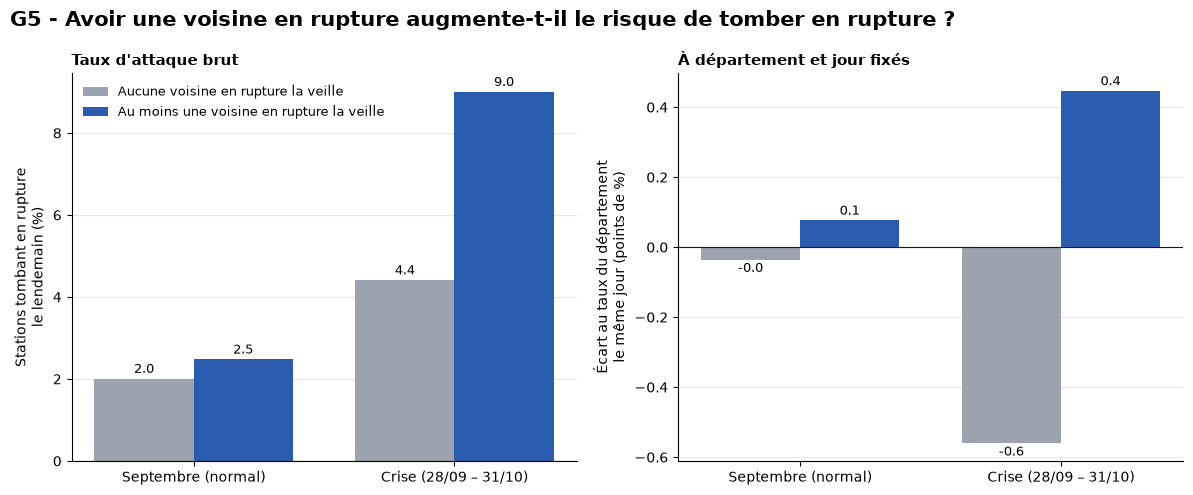

In [20]:
fig = contagion.graphique_taux_attaque(resultats_h2["taux_crise"], resultats_h2["taux_normal"])

En brut (à gauche), l'effet de voisinage paraît fort : pendant la crise, une station dont au moins une voisine était en rupture la veille tombe en rupture deux fois plus souvent (9,0 % contre 4,4 %, sur environ 196 000 observations station-jour). En septembre, l'écart est faible (2,5 % contre 2,0 %).

Mais cette comparaison brute mélange contagion et choc commun : les stations exposées se trouvent surtout dans les départements et les jours les plus touchés. À département et jour fixés (à droite), l'écart entre stations exposées et non exposées tombe à environ 1 point (+0,45 contre −0,56 point). Environ trois quarts de l'écart brut s'expliquent donc par le choc commun au département, ce qui rejoint les résultats de H1.

Il subsiste toutefois un écart propre à la crise : il est environ huit fois plus grand qu'en septembre (0,1 point). Avoir une voisine en rupture augmente donc un peu le risque, au-delà de ce qu'explique la situation du département.

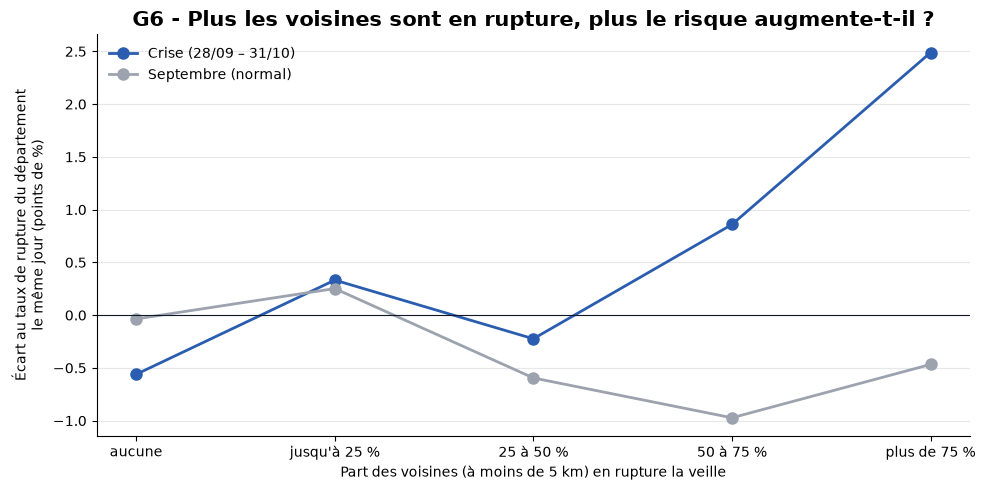

In [21]:
fig = contagion.graphique_dose_reponse(resultats_h2["dose_crise"], resultats_h2["dose_normal"])

En brut, le taux de rupture augmente régulièrement avec la part de voisines en rupture la veille, de 4,4 % (aucune) à 14,2 % (plus de 75 %) pendant la crise (tableau `dose_crise`). Mais à département et jour fixés, la relation n'est pas progressive : l'écart reste proche de zéro tant que moins de la moitié des voisines sont en rupture (entre −0,6 et +0,3 point), puis augmente nettement, à **+0,9 point** quand 50 à 75 % des voisines sont à sec et **+2,5 points** au-delà de 75 %. En septembre, rien de tel : l'écart reste entre −1 et +0,3 point, sans tendance.

L'effet de voisinage apparaît donc comme un **effet de seuil** : il ne se manifeste que lorsque la plupart des stations alentour sont déjà à sec. C'est cohérent avec le mécanisme de report : tant qu'il reste plusieurs stations approvisionnées, la demande se répartit ; quand presque toutes sont vides, les automobilistes se concentrent sur les dernières, qui tombent à leur tour.

Prudence : la classe 50 à 75 % ne compte que 240 observations en septembre, ce qui rend ce point fragile.

**Bilan de H2.** Les données suggèrent une **contagion locale réelle mais secondaire**. L'essentiel de l'association entre la rupture d'une station et celle de ses voisines s'explique par le choc commun au département. À département et jour égaux, il subsiste un effet de voisinage propre à la crise, absent en temps normal, qui n'apparaît que lorsque la majorité des stations voisines sont déjà à sec.

**Limites.**
- **Le contrôle par département ne neutralise pas les chocs plus locaux.** Des stations voisines dépendent souvent du même dépôt, des mêmes tournées de livraison, ou appartiennent à la même enseigne (les stations TotalEnergies, moins chères grâce à leur remise, ont attiré la demande). Une partie de l'effet mesuré peut donc encore venir d'un approvisionnement commun, et non d'un report des clients.
- **Les déclarations de rupture sont imparfaites**, et des fins de rupture déclarées en retard peuvent créer des coïncidences artificielles entre stations voisines.
- **Les écarts sont décrits, pas testés statistiquement.** Ils reposent sur un grand nombre d'observations, mais les stations voisines ne sont pas indépendantes entre elles.

Rapprochés de ceux de H1 (ρ de Spearman = 0,39 entre la distance aux sites en grève et la date de décollage), ces résultats dessinent la même image : un choc logistique commun qui déclenche et structure la crise, amplifié localement par le report des automobilistes lorsque l'offre devient très rare.

## IV. Comparaison avec une vraie épidémie : le COVID-19



**Question.** Si les pénuries se propageaient comme une épidémie, leur courbe devrait ressembler à celle d'une vraie épidémie. Nous comparons la crise des carburants aux deux premières vagues de COVID-19 en France, en 2020.

**Données.** Santé publique France publie les nouvelles hospitalisations quotidiennes pour COVID-19 par département (données SI-VIC, sur data.gouv.fr). Nous gardons la France métropolitaine, comme pour les carburants. Les données ne commencent que le 19 mars 2020 : la montée de la première vague est en partie manquante, alors que la deuxième vague (automne 2020) est observée en entier.

**Méthode.** Nous comparons la forme des courbes, pas leur niveau. Pour les carburants, nous prenons le nombre de stations qui passent en rupture chaque jour (l'incidence) ; pour le COVID, le nombre de nouvelles hospitalisations. Chaque série est lissée sur 7 jours (pour effacer les effets du week-end), recentrée sur son pic (jour 0) et divisée par la valeur de ce pic. Nous mesurons le temps de montée (de la mi-hauteur au pic) et de descente (du pic à la mi-hauteur).

In [22]:
chemin_covid = covid.telecharger_hospitalisations()
df_hosp = covid.lire_hospitalisations(chemin_covid)
serie_covid = covid.serie_nationale(df_hosp)

serie_carburant = df_prev.set_index("jour")["nouvelles_ruptures"]
tableau_formes, courbes = covid.comparer_formes(serie_carburant, serie_covid, ("2022-09-05", "2022-11-30"))
tableau_formes

,date_du_pic,valeur_au_pic,jours_de_montee,jours_de_descente,asymetrie_descente_sur_montee
Carburants 2022 : nouvelles ruptures,2022-10-10,783,7,9,1.3
"COVID-19, 1re vague (printemps 2020)",2020-03-31,3549,11,16,1.5
"COVID-19, 2e vague (automne 2020)",2020-11-06,2844,19,19,1.0


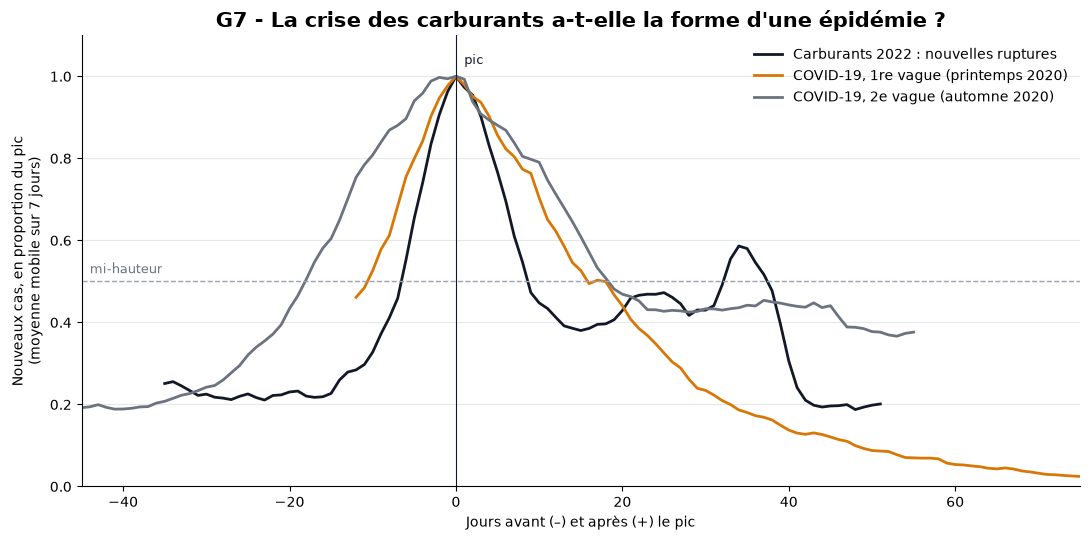

In [23]:
fig = covid.graphique_comparaison(courbes)

La courbe bleue reprend le panneau du bas de G1 (nouvelles ruptures par jour), lissé sur 7 jours et exprimé en proportion de son pic du 10 octobre.

- **Une montée beaucoup plus brutale.** Les nouvelles ruptures passent de la moitié de leur pic au pic en 7 jours, contre 19 jours pour la deuxième vague de COVID-19 et 11 jours pour la première (sous-estimé : le début de la vague n'est pas observé).
- **Une descente plus rapide.** La crise repasse sous la moitié de son pic 9 jours après celui-ci, contre 16 à 19 jours pour le COVID. Son pic est environ deux fois plus étroit.
- **Un retour incomplet et un rebond.** La courbe des carburants ne revient pas à zéro : il subsiste un bruit de fond de ruptures ordinaires (environ 20 % du pic). Elle présente aussi un rebond mi-novembre, sans équivalent dans une vague épidémique.

Cette forme évoque moins une contagion de proche en proche qu'un **choc simultané** : l'arrêt des raffineries et la ruée des automobilistes, partout en même temps, font basculer en quelques jours une grande partie du territoire. C'est cohérent avec les parties précédentes : un démarrage quasi simultané des départements (G2), une diffusion liée à la distance aux sites en grève (G4), et une contagion locale qui reste secondaire (G5, G6).

_Limites :_ nous comparons des phénomènes de nature différente (des stations et des patients), avec des indicateurs différents (déclarations de rupture et admissions à l'hôpital). Les admissions à l'hôpital suivent les contaminations avec un décalage d'environ une à deux semaines, ce qui lisse les courbes COVID. La comparaison porte donc sur l'ordre de grandeur des vitesses, pas sur des valeurs précises.

## Conclusion et limites générales

**Synthèse des résultats.**

| Résultat | Ce qu'il montre | Hypothèse soutenue |
|---|---|---|
| G1 : courbe épidémique | Hausse quelques jours après le début des grèves, pic des nouvelles ruptures le 10 octobre (857 stations), 49,6 % des stations en rupture le 16 octobre | Chronologie liée aux grèves (H1) |
| G2 : carte de chaleur | La plupart des départements basculent en quelques jours début octobre ; le Nord plus tôt, l'Ouest et la Corse presque épargnés | Choc commun, géographie marquée (H1) |
| G4 : distance et décollage | ρ de Spearman = 0,39 (82 départements) : plus un département est loin d'un site en grève, plus il bascule tard | H1 |
| G5 : taux d'attaque | Effet brut fort (9,0 % contre 4,4 %), mais réduit à environ 1 point à département et jour fixés ; cet écart est environ 8 fois plus grand qu'en septembre | H2, effet secondaire |
| G6 : dose-réponse | Effet de voisinage seulement quand plus de la moitié des voisines sont à sec (+2,5 points au-delà de 75 %) | H2, effet de seuil |
| G7 : comparaison COVID | Montée environ 3 fois plus rapide qu'une vague épidémique, pic plus étroit | Choc simultané plutôt que contagion |

Les pénuries d'octobre 2022 ne se sont pas principalement propagées comme une épidémie. Les données suggèrent plutôt un choc logistique commun : la crise démarre quelques jours après les grèves, touche la plupart des départements presque en même temps, plus tôt près des sites en grève, et s'emballe beaucoup plus vite qu'une épidémie. Un mécanisme de contagion locale existe néanmoins : quand la plupart des stations alentour sont à sec, les automobilistes se reportent sur les dernières stations approvisionnées, qui tombent à leur tour. Il amplifie la crise localement, sans en être le moteur.

**Limites générales.**
- **L'indicateur de rupture** repose sur des déclarations des stations, parfois tardives ou imprécises ; il surestime le niveau de la pénurie par rapport aux chiffres officiels, mais en restitue bien la chronologie.
- **La géographie de l'approvisionnement est approchée par la distance à vol d'oiseau** : nous ne connaissons ni les circuits réels de livraison, ni le dépôt dont dépend chaque station.
- **L'enseigne des stations est absente des données**, alors que la remise de TotalEnergies a probablement concentré la demande sur ses stations.
- **Nos résultats sont descriptifs** : ils décrivent des associations, sans établir de causalité.

**Prolongements possibles.** Avec l'enseigne et le dépôt d'approvisionnement de chaque station, on pourrait séparer plus nettement le choc logistique du report des automobilistes. La même démarche pourrait aussi s'appliquer à d'autres pénuries (mouvement contre la loi Travail en 2016, par exemple) pour voir si ce schéma se répète.